# 01. 이미지 축 변환과 matplotlib 표시
`20261102/02_응용/01_axes.py`를 바탕으로 **CHW → HWC → matplotlib 표시 → NCHW** 흐름을 확인합니다.

## 0. 작업 전 준비사항
이 실습은 CPU로 충분합니다. PyTorch, torchvision, Pillow, matplotlib이 설치된 Python 커널을 선택한 뒤 **Run All(모두 실행)**로 위에서 아래로 실행합니다. 커널을 재시작했다면 첫 코드 셀부터 다시 실행합니다.

이미지는 기존 `02_응용/data/train/horizontal` 폴더의 RGB PNG를 사용합니다. 저장소 루트, `20261102`, `docs`, `02_응용`에서 실행해도 상위 경로를 탐색해 데이터를 찾습니다. Jupyter에서는 `__file__` 대신 `Path.cwd()`를 사용합니다.

이 노트북은 이미지를 셀 출력에 표시하고 `20261102/02_응용/docs/outputs/image_axes.png`로 저장합니다. 원본 Python 파일의 `Agg` 백엔드는 파일 저장용이며, 여기서는 `%matplotlib inline`으로 노트북 안에 표시합니다.

In [1]:
%matplotlib inline
from pathlib import Path
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(1)
print("PyTorch 버전:", torch.__version__)
print("실습 장치: CPU")

PyTorch 버전: 2.14.0+cu130
실습 장치: CPU


## 1. 파일 불러오기 및 CHW 텐서 준비
`convert("RGB")`로 채널을 R/G/B 세 개로 맞춥니다. 이 실습의 8비트 PNG에 `ToTensor()`를 적용하면 픽셀값이 0~1 범위의 `float32`로 변환되고, 축 순서는 **CHW**가 됩니다.

| 기호 | 의미 | 이번 이미지 크기 |
| --- | --- | --- |
| N | 배치에 포함된 이미지 수 | 1 |
| C | 색상 채널 수 | 3 |
| H | 이미지 높이 | 64 |
| W | 이미지 너비 | 64 |

In [2]:
cwd = Path.cwd().resolve()
candidates = [candidate
              for parent in (cwd, *cwd.parents)
              for candidate in (parent / "20261102", parent)]
day_root = next((candidate for candidate in candidates
                 if (candidate / "02_응용" / "data" / "train" / "horizontal").is_dir()), None)
if day_root is None:
    raise FileNotFoundError("저장소 안에서 실행하고 20261102/02_응용/data 경로를 확인하세요.")

image_paths = sorted((day_root / "02_응용" / "data" / "train" / "horizontal").glob("*.png"))
if not image_paths:
    raise FileNotFoundError("horizontal 폴더에 PNG 이미지가 없습니다.")
path = image_paths[0]
with Image.open(path) as image:
    chw = transforms.ToTensor()(image.convert("RGB"))
print("입력 이미지:", path.name)
print("CHW:", tuple(chw.shape))
print("dtype:", chw.dtype)
print("픽셀값 범위:", chw.min().item(), "~", chw.max().item())

입력 이미지: train_horizontal_000.png
CHW: (3, 64, 64)
dtype: torch.float32
픽셀값 범위: 0.08627451211214066 ~ 0.7215686440467834


## 축 순서를 바꾸는 이유
이미지 도구마다 입력을 해석하는 축 순서가 다르기 때문에, 같은 픽셀값을 각 도구의 입력 형식에 맞춰 전달합니다.

| 단계 | 형태 | 사용하는 이유 |
| --- | --- | --- |
| `ToTensor()` 결과 | CHW `(3, 64, 64)` | torchvision이 RGB 이미지를 채널 우선 텐서로 변환합니다. |
| matplotlib 표시 | HWC `(64, 64, 3)` | `imshow()`는 RGB 이미지를 높이·너비·색상 채널 순서로 해석합니다. |
| CNN 배치 입력 | NCHW `(1, 3, 64, 64)` | PyTorch `Conv2d`의 배치 입력은 이미지 수·채널·높이·너비 순서입니다. |

### 왜 CHW → HWC → NCHW 순서로 실습하나요?
먼저 **이미지를 눈으로 확인**하기 위해 CHW를 HWC로 바꿉니다. 그다음 **CNN에 넣을 배치 형태를 준비**하기 위해 다시 CHW 순서로 되돌리고, 이미지 수를 나타내는 N 축을 추가합니다. 이 실습은 표시용 형식과 모델 입력용 형식의 차이를 한 흐름으로 보여 주고, 왕복해도 값이 유지되는지 확인하기 위한 구성입니다. 이 파일에서는 NCHW를 준비하고 확인하는 단계까지만 수행하며 CNN에 실제로 입력하지는 않습니다.

### 실제로도 반드시 HWC를 거쳐야 하나요?
HWC를 거칠 필요는 없습니다. 표시와 모델 입력은 원본 CHW에서 각각 준비할 수 있습니다.

```python
hwc = chw.permute(1, 2, 0)  # matplotlib 표시용
nchw = chw.unsqueeze(0)     # CNN 배치 입력용
```

위의 `chw.unsqueeze(0)`은 실습의 `hwc.permute(2, 0, 1).unsqueeze(0)`과 같은 shape와 값을 만듭니다. 여러 이미지가 있다면 `torch.stack([chw1, chw2], dim=0)`으로 NCHW 배치를 만들거나, Dataset이 CHW 이미지를 반환하도록 한 뒤 DataLoader의 기본 배치 묶기를 사용할 수 있습니다.

### 이미지 자체가 달라지나요?
이 과정은 축의 순서와 배치 차원만 바꿉니다. 리사이즈, 색상 변경, 정규화는 수행하지 않습니다. `permute()`는 데이터를 공유하면서 축 순서에 따른 접근 방식을 바꾸고, `unsqueeze(0)`은 크기 1인 축을 추가합니다. 따라서 첫 배치 이미지 `nchw[0]`은 원본 `chw`와 값이 같습니다.

참고로 `Conv2d`는 배치 축이 없는 CHW 입력도 지원합니다. 여러 이미지를 함께 처리하는 일반적인 학습에서는 NCHW를 사용하며, 이 실습도 그 형태를 준비합니다.


## 2. CHW → HWC 변환과 matplotlib 표시
`permute(1, 2, 0)`은 기존 축 1(H), 2(W), 0(C) 순서로 텐서를 봅니다. 픽셀값과 이미지 내용은 유지됩니다. 축 순서를 바꾸려면 `reshape()` 대신 `permute()`를 사용합니다.

matplotlib의 `imshow()`는 RGB 이미지를 **(H, W, 3)** 순서로 받습니다. 따라서 CHW 텐서를 HWC로 바꾸고, CPU 텐서를 `numpy()`로 변환해 전달합니다. 이 예제의 텐서는 CPU에 있고 기울기를 추적하지 않으므로 바로 `numpy()`를 사용할 수 있습니다. GPU 또는 기울기 추적 텐서를 표시할 때는 `detach().cpu().numpy()`를 사용합니다.

`set_axis_off()`는 눈금과 테두리를 숨기고, `tight_layout()`은 여백을 조정합니다. `savefig()`로 파일을 저장한 뒤 `show()`로 노트북에 표시하고 `close()`로 그림을 정리합니다.

HWC: (64, 64, 3)


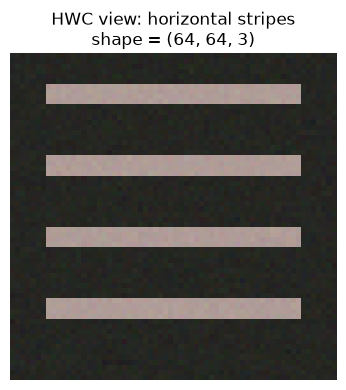

이미지 저장: /home/swchoi/projects/python/practice_assignment/20261102/02_응용/docs/outputs/image_axes.png


In [3]:
# 기존 축 번호: C=0, H=1, W=2
hwc = chw.permute(1, 2, 0)
print("HWC:", tuple(hwc.shape))

out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
image_path = out / "image_axes.png"

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(hwc.numpy())
ax.set_title(f"HWC view: horizontal stripes\nshape = {tuple(hwc.shape)}")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(image_path, dpi=120)
plt.show()
plt.close(fig)
print("이미지 저장:", image_path)

## 3. HWC → NCHW 변환 및 값 확인
PyTorch의 `Conv2d`에 배치 입력을 전달할 때는 **NCHW** 순서를 사용합니다.

1. `hwc.permute(2, 0, 1)`로 HWC를 CHW로 되돌립니다.
2. `unsqueeze(0)`으로 맨 앞에 크기 1인 배치 축 N을 추가합니다.
3. `nchw[0]`으로 첫 번째 이미지를 꺼내 원래 CHW와 값이 같은지 확인합니다.

`unsqueeze(0)`은 이미지를 복사해서 늘리는 연산이 아니라 크기가 1인 축을 추가하는 연산입니다.

In [4]:
nchw = hwc.permute(2, 0, 1).unsqueeze(0)
print("CHW / HWC / NCHW:", tuple(chw.shape), tuple(hwc.shape), tuple(nchw.shape))
print("왕복 값 일치:", torch.equal(chw, nchw[0]))

assert tuple(hwc.shape) == (chw.shape[1], chw.shape[2], chw.shape[0])
assert tuple(nchw.shape) == (1, *chw.shape)
assert torch.equal(chw, nchw[0])

CHW / HWC / NCHW: (3, 64, 64) (64, 64, 3) (1, 3, 64, 64)
왕복 값 일치: True


## 4. 결과 해석 및 추가 실험
기본 데이터에서는 다음 결과가 나옵니다.

```text
CHW / HWC / NCHW: (3, 64, 64) (64, 64, 3) (1, 3, 64, 64)
왕복 값 일치: True
```

출력 이미지에서 수평 줄무늬를 확인합니다. 같은 픽셀값을 유지하면서 축의 배치만 바꿨기 때문에, NCHW에서 배치 축을 꺼낸 결과는 원본 CHW와 같습니다.

### 직접 확인해 볼 내용
- 입력 폴더를 `vertical`로 바꿔 세로 줄무늬가 표시되는지 확인합니다.
- `hwc.permute(1, 0, 2)`를 표시하면 H와 W의 역할이 바뀌어 줄무늬 방향이 어떻게 달라지는지 관찰합니다. 이 데이터는 정사각형이므로 shape가 같아도 이미지 내용의 배치는 달라질 수 있습니다.
- `torch.stack([chw, chw], dim=0)`으로 이미지 두 장을 묶고 `(2, 3, 64, 64)`가 되는지 확인합니다.

### 자주 하는 실수 점검
- `imshow()`에 `(3, H, W)`를 그대로 넣지 않았는가?
- `permute()`의 인자를 기존 축 번호 기준으로 작성했는가?
- `reshape()`로 축 교환을 대신하지 않았는가?
- 배치 축을 맨 앞에 추가했는가?
- 파일 저장만 하는 원본 스크립트의 `Agg` 설정과 노트북의 인라인 표시를 구분했는가?